# Train one-hour-ahead effluent NH3-N and NO3-N forecasts

Use notebook 01's seven-day **observed-only 20-minute aggregate**, `data_filled_20min.csv`. Each input row is available at its bin-end timestamp; predict the mean effluent measurement in the bin ending one hour later. The project calls the ammonia task `eff_nh3_n` and measures its configured `Eff_NH4_N` target.

Train a fixed-parameter XGBoost model for each target and compare with current-value persistence. Reserve the latest 20% of forecast origins for testing and purge training labels unavailable at the first test origin. No random split, test-set tuning, target interpolation, or additional null filling occurs. This is an exploratory holdout: notebook 01 selected the seven-day window using completeness across the whole interval. Confirm performance on a separate later period before deployment.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
import xgboost
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "config" / "sensors.py").is_file()), None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Launch from the repository root or notebooks directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from config.eff_nh3_n import CONFIG as NH3_CONFIG
from config.eff_no3_n import CONFIG as NO3_CONFIG
MODEL_CONFIGS = {cfg["name"]: cfg for cfg in (NH3_CONFIG, NO3_CONFIG)}

DATA_PATH = PROJECT_ROOT / "notebooks/data/data_filled_20min.csv"
COUNTS_PATH = PROJECT_ROOT / "notebooks/data/data_filled_20min_observed_counts.csv"
OUTPUT_DIR = PROJECT_ROOT / "notebooks/data/effluent_training_20min"
CADENCE = pd.Timedelta(minutes=20)
FORECAST_HORIZON = pd.Timedelta(hours=1)
TRAIN_FRACTION = 0.80
XGB_PARAMETERS = {
    "objective": "reg:squarederror", "n_estimators": 300,
    "learning_rate": 0.03, "max_depth": 3, "min_child_weight": 2,
    "subsample": 0.85, "colsample_bytree": 0.8,
    "reg_alpha": 0.0, "reg_lambda": 2.0,
    "random_state": 42, "n_jobs": 1, "tree_method": "hist",
}


## Validate source data and observation support

CSV columns use configured SQL aliases. The aggregate contains raw observations only, so a minute-level interpolation mask does not apply. Its companion counts record actual readings contributing to each bin. Require a regular timeline, complete numeric values, and positive observation counts. Keep the 20-minute resolution instead of upsampling it into artificial ten-minute observations.


In [2]:
data = pd.read_csv(DATA_PATH, encoding="utf-8-sig", index_col="available_at", parse_dates=True)
observed_counts = pd.read_csv(COUNTS_PATH, index_col="available_at", parse_dates=True)
if data.empty or not isinstance(data.index, pd.DatetimeIndex):
    raise ValueError("Expected nonempty data indexed by bin-end availability timestamps.")
if not data.index.is_unique or not data.index.is_monotonic_increasing:
    raise ValueError("Timestamps must be unique and increasing.")
if not data.index.to_series().diff().dropna().eq(CADENCE).all():
    raise ValueError("The input must be a continuous 20-minute timeline.")
if not data.index.equals(observed_counts.index) or list(data.columns) != list(observed_counts.columns):
    raise ValueError("Observed counts and data must align exactly.")
data = data.apply(pd.to_numeric, errors="raise")
if not np.isfinite(data.to_numpy()).all() or not observed_counts.ge(1).all().all():
    raise ValueError("Expected finite observed means with positive support for every bin.")
if not 0 < TRAIN_FRACTION < 1 or FORECAST_HORIZON % CADENCE:
    raise ValueError("Invalid train fraction or horizon/cadence combination.")
for name, cfg in MODEL_CONFIGS.items():
    missing = set(cfg["features"] + [cfg["target"]]) - set(data.columns)
    if missing:
        raise ValueError(f"{name} missing configured columns: {missing}")
print(f"Loaded {len(data)} bins × {len(data.columns)} sensors.")
print(f"Available at: {data.index.min()} through {data.index.max()}")
print(f"Minimum raw readings per sensor/bin: {observed_counts.min().min()}")
display(data[[NH3_CONFIG["target"], NO3_CONFIG["target"]]].describe())


Loaded 504 bins × 30 sensors.
Available at: 2026-04-03 23:05:00 through 2026-04-10 22:45:00
Minimum raw readings per sensor/bin: 5


,Eff_NH4_N,Eff_NO3_N
count,504.000000,504.0
mean,0.191618,5.0
std,0.005647,0.0
min,0.175802,5.0
25%,0.187677,5.0
50%,0.191385,5.0
75%,0.195187,5.0
max,0.208697,5.0


## Build future labels and purge the chronological split

Use configured current-bin features plus the model's current effluent measurement as an autoregressive input. Match the future target by **timestamp** exactly one hour later. Observation counts are diagnostics, not additional model inputs.

Training labels must end no later than the first test forecast origin. This permits a label that becomes available exactly at that origin, before issuing its forecast. Test predictions use newly available current observations sequentially; this is rolling one-hour-ahead evaluation, not a single fixed-origin forecast of the entire test period.


In [3]:
splits = {}
model_datasets = {}
split_records = []
for name, cfg in MODEL_CONFIGS.items():
    target = cfg["target"]
    current_column = f"{target}__current"
    frame = data[cfg["features"]].copy()
    frame[current_column] = data[target]
    label_times = frame.index + FORECAST_HORIZON
    frame["future_target"] = data[target].reindex(label_times).to_numpy()
    frame = frame.loc[frame["future_target"].notna()].copy()
    split_position = int(len(frame) * TRAIN_FRACTION)
    if not 1 <= split_position < len(frame):
        raise ValueError("Not enough data for a chronological split.")
    test = frame.iloc[split_position:].copy()
    first_test_origin = test.index.min()
    train = frame.iloc[:split_position].copy()
    train = train.loc[train.index + FORECAST_HORIZON <= first_test_origin]
    if train.empty or len(test) < 2:
        raise ValueError("Insufficient rows after purging.")
    inputs = [*cfg["features"], current_column]
    assert train.index.max() + FORECAST_HORIZON <= test.index.min()
    assert train.index.intersection(test.index).empty
    splits[name] = {
        "X_train": train[inputs], "y_train": train["future_target"],
        "X_test": test[inputs], "y_test": test["future_target"],
        "current_column": current_column,
    }
    model_datasets[name] = frame
    split_records.append({
        "model": name, "target": target, "inputs": len(inputs),
        "train_rows": len(train), "test_rows": len(test),
        "purged_rows": split_position - len(train),
        "first_train_origin": train.index.min(), "last_train_origin": train.index.max(),
        "last_train_label_available": train.index.max() + FORECAST_HORIZON,
        "first_test_origin": test.index.min(), "last_test_origin": test.index.max(),
        "last_test_label_available": test.index.max() + FORECAST_HORIZON,
        "train_target_unique": train["future_target"].nunique(),
        "test_target_unique": test["future_target"].nunique(),
    })
split_summary = pd.DataFrame(split_records).set_index("model")
display(split_summary)


,target,inputs,train_rows,test_rows,purged_rows,first_train_origin,last_train_origin,last_train_label_available,first_test_origin,last_test_origin,last_test_label_available,train_target_unique,test_target_unique
model,,,,,,,,,,,,,
eff_nh3_n,Eff_NH4_N,17,398,101,2,2026-04-03 23:05:00,2026-04-09 11:25:00,2026-04-09 12:25:00,2026-04-09 12:25:00,2026-04-10 21:45:00,2026-04-10 22:45:00,392,100
eff_no3_n,Eff_NO3_N,22,398,101,2,2026-04-03 23:05:00,2026-04-09 11:25:00,2026-04-09 12:25:00,2026-04-09 12:25:00,2026-04-10 21:45:00,2026-04-10 22:45:00,1,1


## Fit both models and compare with persistence

Use fixed parameters without tuning on the held-out test period. Report MAE, RMSE, bias and R² in the original target units. R² is undefined for constant actual targets. A positive skill score means lower error than persistence; skill is undefined when the baseline error is zero. A constant NO3 target cannot validate forecasting of nitrate changes.


In [4]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return {
        "N": len(actual),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(mean_squared_error(actual, predicted) ** 0.5),
        "Bias": float(np.mean(predicted - actual)),
        "R2": float(r2_score(actual, predicted)) if np.unique(actual).size > 1 else np.nan,
    }

models = {}
predictions = {}
metric_records = []
importance_tables = {}
for name, split in splits.items():
    model = XGBRegressor(**XGB_PARAMETERS)
    model.fit(split["X_train"], split["y_train"])
    models[name] = model
    results = pd.DataFrame({
        "forecast_origin": split["X_test"].index,
        "target_available_at": split["X_test"].index + FORECAST_HORIZON,
        "actual": split["y_test"].to_numpy(),
        "xgboost": model.predict(split["X_test"]),
        "persistence": split["X_test"][split["current_column"]].to_numpy(),
    }).set_index("forecast_origin")
    predictions[name] = results
    baseline = regression_metrics(results["actual"], results["persistence"])
    for estimator in ("xgboost", "persistence"):
        metrics = regression_metrics(results["actual"], results[estimator])
        for metric in ("MAE", "RMSE"):
            metrics[f"{metric}_skill_pct"] = (
                100 * (1 - metrics[metric] / baseline[metric])
                if baseline[metric] > 0 else np.nan
            )
        metric_records.append({"model": name, "estimator": estimator, **metrics})
    importance_tables[name] = pd.DataFrame({
        "feature": split["X_train"].columns, "importance": model.feature_importances_,
    }).sort_values("importance", ascending=False)
    if split["y_train"].nunique() == 1:
        print(f"{name}: training target is constant; persistence is the meaningful reference.")
metrics_table = pd.DataFrame(metric_records).set_index(["model", "estimator"])
display(metrics_table.style.format(precision=6, na_rep="undefined"))
for name, importance in importance_tables.items():
    print(name, "top fitted feature importances (not causal effects)")
    display(importance.head(10))


eff_no3_n: training target is constant; persistence is the meaningful reference.


eff_nh3_n top fitted feature importances (not causal effects)


,feature,importance
15,Q_A2_air,0.149329
9,A1_O_MLSS,0.103750
2,A1_COD_in,0.069866
7,A1_O_ORP,0.067770
16,Eff_NH4_N__current,0.066747
11,A2_O_ORP,0.065773
0,A1_Qin,0.064981
12,A2_O_DO,0.057846
14,Q_A1_air,0.056841
6,A1_O_PH,0.055600


eff_no3_n top fitted feature importances (not causal effects)


,feature,importance
0,A1_Qin,0.0
1,A2_Qin,0.0
2,A1_COD_in,0.0
3,A1_FQ_CH3OH,0.0
4,A1_Q_r1,0.0
5,A2_COD_in,0.0
6,A2_Q_r1,0.0
7,A2_FQ_CH3OH,0.0
8,A1_NH3_N,0.0
9,A2_NH3_N,0.0


## Test-set actual versus predicted values

Compare the observed test targets with XGBoost predictions at the same future target bin-end timestamps. Each target has one time-series plot. For constant NO3 values, the two series overlap.


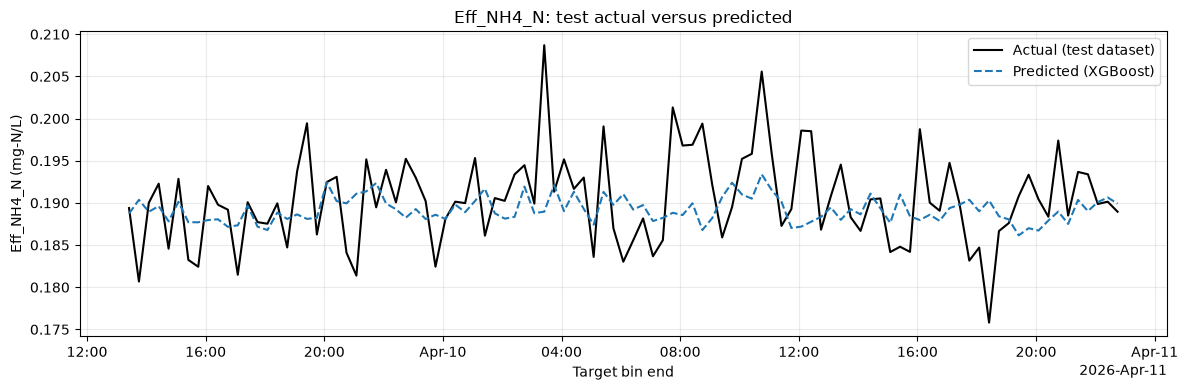

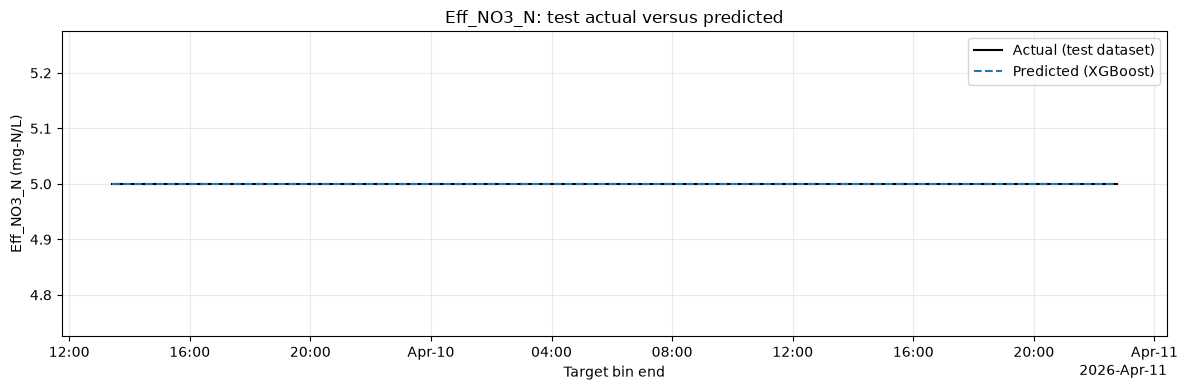

In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, cfg in MODEL_CONFIGS.items():
    results = predictions[name]
    target_times = results["target_available_at"]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(target_times, results["actual"], color="black", linewidth=1.5,
            label="Actual (test dataset)")
    ax.plot(target_times, results["xgboost"], color="tab:blue", linewidth=1.5,
            linestyle="--", label="Predicted (XGBoost)")
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end", ylabel=f"{cfg['target']} (mg-N/L)",
           title=f"{cfg['target']}: test actual versus predicted")
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_evaluation.png", dpi=150, bbox_inches="tight")
    plt.show()


## Training, test and prediction overview

Show observed training targets, observed test targets and held-out predictions together. Green shading marks training labels, amber marks labels removed by horizon purging, and blue marks test labels. All readings are plotted at their **target bin-end timestamp**, one hour after their forecast origin; the dashed boundary marks the first test target. It is therefore one hour later than the first test forecast origin shown in the split table. No fitted training predictions are included.


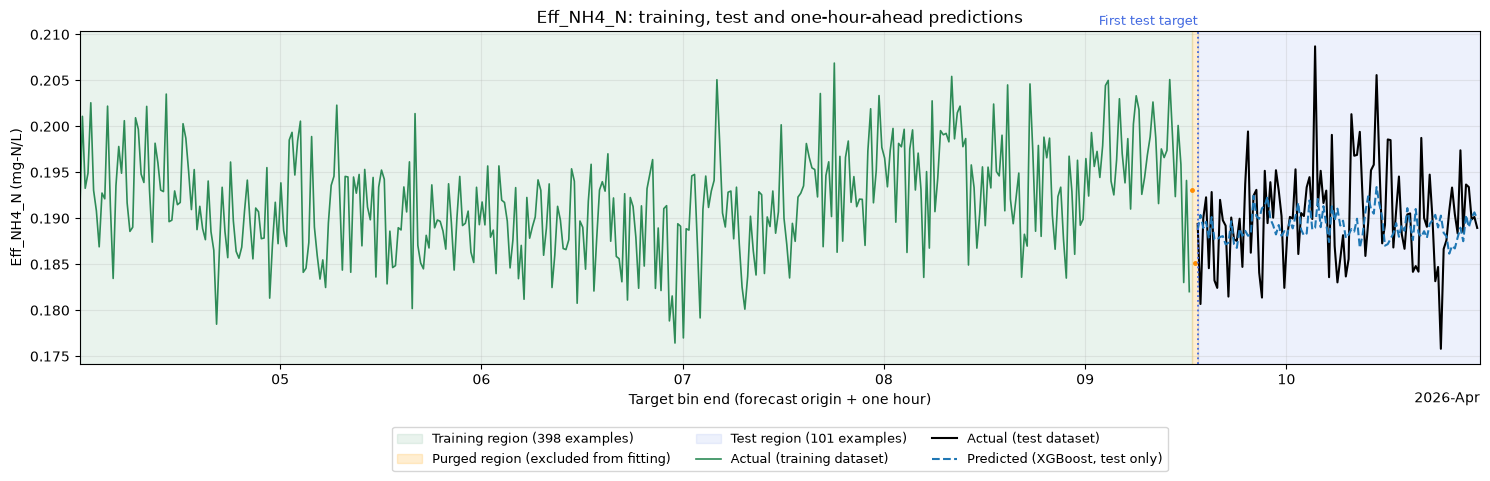

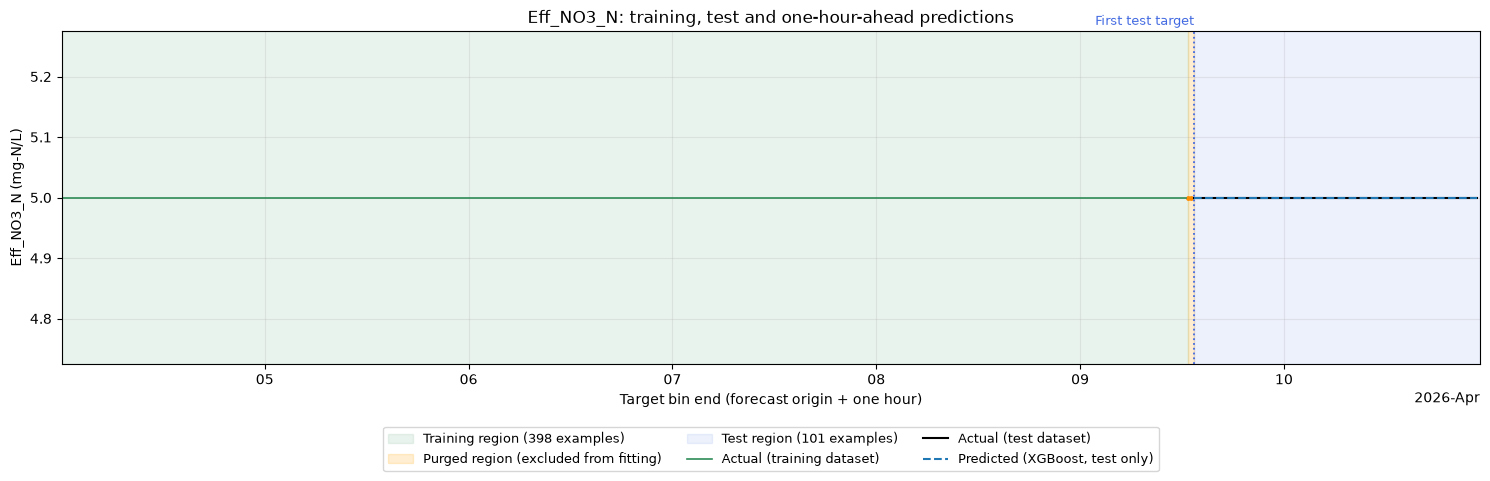

In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, cfg in MODEL_CONFIGS.items():
    train_actual = splits[name]["y_train"]
    results = predictions[name]
    train_times = train_actual.index + FORECAST_HORIZON
    test_times = pd.DatetimeIndex(results["target_available_at"])
    train_region_end = train_times.max() + CADENCE
    test_region_start = test_times.min()
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.axvspan(train_times.min(), train_region_end, color="seagreen", alpha=0.10,
               label=f"Training region ({len(train_actual)} examples)")
    if train_region_end < test_region_start:
        ax.axvspan(train_region_end, test_region_start, color="orange", alpha=0.18,
                   label="Purged region (excluded from fitting)")
        excluded = model_datasets[name]["future_target"]
        excluded_times = excluded.index + FORECAST_HORIZON
        purged = (excluded_times >= train_region_end) & (excluded_times < test_region_start)
        ax.plot(excluded_times[purged], excluded.loc[purged], ".", color="darkorange",
                markersize=5)
    ax.axvspan(test_region_start, test_times.max() + CADENCE,
               color="royalblue", alpha=0.09,
               label=f"Test region ({len(results)} examples)")
    ax.plot(train_times, train_actual, color="seagreen", linewidth=1.2,
            label="Actual (training dataset)")
    ax.plot(test_times, results["actual"], color="black", linewidth=1.5,
            label="Actual (test dataset)")
    ax.plot(test_times, results["xgboost"], color="tab:blue", linestyle="--",
            linewidth=1.5, label="Predicted (XGBoost, test only)")
    ax.axvline(test_region_start, color="royalblue", linestyle=":", linewidth=1.3)
    ax.text(test_region_start, 1.01, "First test target", transform=ax.get_xaxis_transform(),
            color="royalblue", fontsize=9, ha="right", va="bottom")
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end (forecast origin + one hour)",
           ylabel=f"{cfg['target']} (mg-N/L)",
           title=f"{cfg['target']}: training, test and one-hour-ahead predictions")
    ax.set_xlim(train_times.min(), test_times.max() + CADENCE)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_train_test_overview.png", dpi=150, bbox_inches="tight")
    plt.show()


## Save models, predictions and reproducibility information

Save the evaluated training-only models (no refit on test data), metrics, split dates, feature importances and source hashes in `notebooks/data/effluent_training_20min/`. Rerunning replaces these local files. The data directory is ignored by Git. Model metadata defines the availability timestamps, input feature order, cadence and horizon needed to interpret predictions.


In [7]:
metrics_table.to_csv(OUTPUT_DIR / "metrics.csv")
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv")
for name, model in models.items():
    model.save_model(OUTPUT_DIR / f"{name}.ubj")
    predictions[name].to_csv(OUTPUT_DIR / f"{name}_test_predictions.csv")
    importance_tables[name].to_csv(OUTPUT_DIR / f"{name}_feature_importance.csv", index=False)
metadata = {
    "data_path": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "observed_counts_sha256": hashlib.sha256(COUNTS_PATH.read_bytes()).hexdigest(),
    "source_interval_start_inclusive": str(data.index.min() - CADENCE),
    "source_interval_end_exclusive": str(data.index.max()),
    "cadence": str(CADENCE), "forecast_horizon": str(FORECAST_HORIZON),
    "timestamp_semantics": "bin-end availability; future label ends origin + horizon",
    "train_fraction_before_purge": TRAIN_FRACTION,
    "parameters": XGB_PARAMETERS,
    "features": {name: list(split["X_train"].columns) for name, split in splits.items()},
    "targets": {name: cfg["target"] for name, cfg in MODEL_CONFIGS.items()},
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "xgboost": xgboost.__version__,
                 "scikit_learn": sklearn.__version__},
    "limitations": ["single seven-day completeness-selected window", "no hyperparameter tuning",
                    "constant NO3 target", "requires independent later-period validation"],
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
# Check that saved models reproduce held-out predictions.
for name in models:
    restored = XGBRegressor()
    restored.load_model(OUTPUT_DIR / f"{name}.ubj")
    np.testing.assert_allclose(restored.predict(splits[name]["X_test"]),
                               predictions[name]["xgboost"], rtol=1e-6)
print(f"Saved and verified both models and evaluation artifacts in {OUTPUT_DIR}")


Saved and verified both models and evaluation artifacts in /home/bryan1010/projects/ao-mbr-data-pipeline/notebooks/data/effluent_training_20min


## Compare forecasting algorithms

Compare **Ridge regression** (a regularized linear reference), **Random Forest** (averaged decision trees), and **Extra Trees** (more randomized trees) with XGBoost and persistence. These supervised regressors use exactly the same configured sensor inputs, current target, one-hour labels and purged chronological split. Ridge scaling is fitted inside its training-only pipeline. Fixed settings are used without tuning on the test set.

This is a demonstration comparison on one small holdout, not independent confirmation of the best algorithm. Comparing models repeatedly on this test set makes it unsuitable as the final unbiased evaluation set. Use a separate later period before model selection or deployment. NO3's constant observations cannot establish forecasting skill.

References: [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html), [Extra Trees](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesRegressor.html), [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).


In [8]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib

ESTIMATOR_LABELS = {
    "xgboost": "XGBoost", "random_forest": "Random Forest",
    "extra_trees": "Extra Trees", "ridge": "Ridge", "persistence": "Persistence",
}
ESTIMATOR_COLORS = {
    "xgboost": "tab:blue", "random_forest": "tab:purple",
    "extra_trees": "tab:red", "ridge": "tab:orange",
}
comparison_models = {}
comparison_predictions = {}
comparison_records = []
for name, split in splits.items():
    fitted = {"xgboost": models[name]}
    candidates = {
        "random_forest": RandomForestRegressor(
            n_estimators=300, max_depth=6, min_samples_leaf=3,
            random_state=42, n_jobs=1,
        ),
        "extra_trees": ExtraTreesRegressor(
            n_estimators=300, max_depth=6, min_samples_leaf=3,
            random_state=42, n_jobs=1,
        ),
        "ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    }
    results = predictions[name].copy()
    for key, estimator in candidates.items():
        estimator.fit(split["X_train"], split["y_train"])
        results[key] = estimator.predict(split["X_test"])
        fitted[key] = estimator
    comparison_models[name] = fitted
    comparison_predictions[name] = results
    reference = regression_metrics(results["actual"], results["persistence"])
    for key, label in ESTIMATOR_LABELS.items():
        metrics = regression_metrics(results["actual"], results[key])
        for metric in ("MAE", "RMSE"):
            metrics[f"{metric}_skill_pct"] = (
                100 * (1 - metrics[metric] / reference[metric])
                if reference[metric] > 0 else np.nan
            )
        comparison_records.append({"target": name, "algorithm": label, **metrics})
comparison_metrics = pd.DataFrame(comparison_records).set_index(["target", "algorithm"])
for name in MODEL_CONFIGS:
    print(name, "— identical held-out observations for every algorithm")
    display(comparison_metrics.loc[name].sort_values("MAE", kind="stable")
            .style.format(precision=6, na_rep="undefined"))
print("Lower MAE/RMSE is better; positive skill beats persistence; constant-target R² is undefined.")


eff_nh3_n — identical held-out observations for every algorithm


,N,MAE,RMSE,Bias,R2,MAE_skill_pct,RMSE_skill_pct
algorithm,,,,,,,
Random Forest,101,0.004053,0.005405,-0.000224,-0.016305,29.333499,25.434770
Extra Trees,101,0.004155,0.005540,-0.000131,-0.067760,27.546643,23.570460
XGBoost,101,0.004171,0.005532,-0.001181,-0.064584,27.279697,23.684202
Ridge,101,0.004424,0.005747,0.000810,-0.149082,22.855442,20.713358
Persistence,101,0.005735,0.007248,-0.000086,-0.827895,0.000000,0.000000


eff_no3_n — identical held-out observations for every algorithm


,N,MAE,RMSE,Bias,R2,MAE_skill_pct,RMSE_skill_pct
algorithm,,,,,,,
XGBoost,101,0.000000,0.000000,0.000000,undefined,undefined,undefined
Random Forest,101,0.000000,0.000000,0.000000,undefined,undefined,undefined
Extra Trees,101,0.000000,0.000000,0.000000,undefined,undefined,undefined
Ridge,101,0.000000,0.000000,0.000000,undefined,undefined,undefined
Persistence,101,0.000000,0.000000,0.000000,undefined,undefined,undefined


Lower MAE/RMSE is better; positive skill beats persistence; constant-target R² is undefined.


## Model comparison over time: test dataset

Use the same test-only timeline format as above: actual target values and all four model predictions, aligned to future bin ends. Persistence remains in the metrics table as the reference. The NO3 lines overlap because its target is constant.


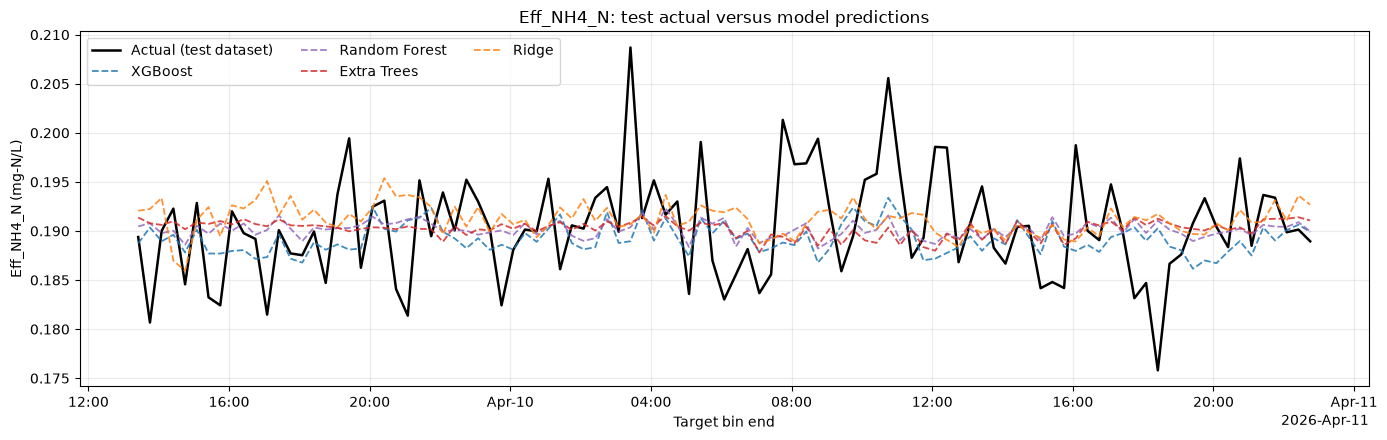

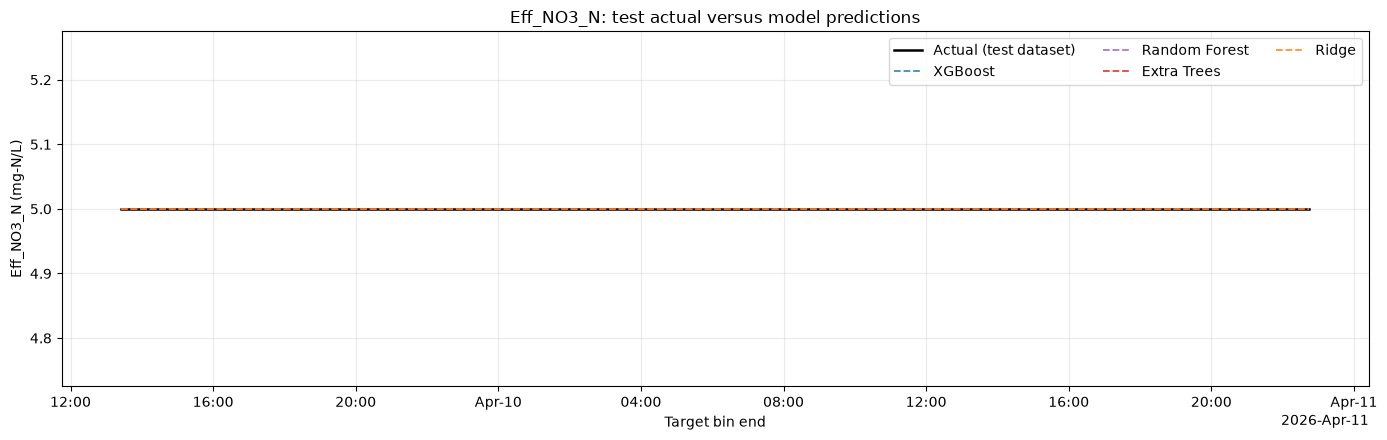

In [9]:
for name, cfg in MODEL_CONFIGS.items():
    results = comparison_predictions[name]
    times = results["target_available_at"]
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(times, results["actual"], color="black", linewidth=1.8,
            label="Actual (test dataset)")
    for key, color in ESTIMATOR_COLORS.items():
        ax.plot(times, results[key], color=color, linewidth=1.3,
                linestyle="--", alpha=0.85, label=ESTIMATOR_LABELS[key])
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end", ylabel=f"{cfg['target']} (mg-N/L)",
           title=f"{cfg['target']}: test actual versus model predictions")
    ax.grid(True, alpha=0.25)
    ax.legend(ncol=3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_algorithm_comparison_test.png", dpi=150, bbox_inches="tight")
    plt.show()


## Model comparison with highlighted train/test regions

Keep the same target-time axis and training/purge/test shading as the earlier overview. Plot only held-out model predictions; the green actual series supplies the training context. The test boundary marks the first test **target**, one hour after the first forecast origin.


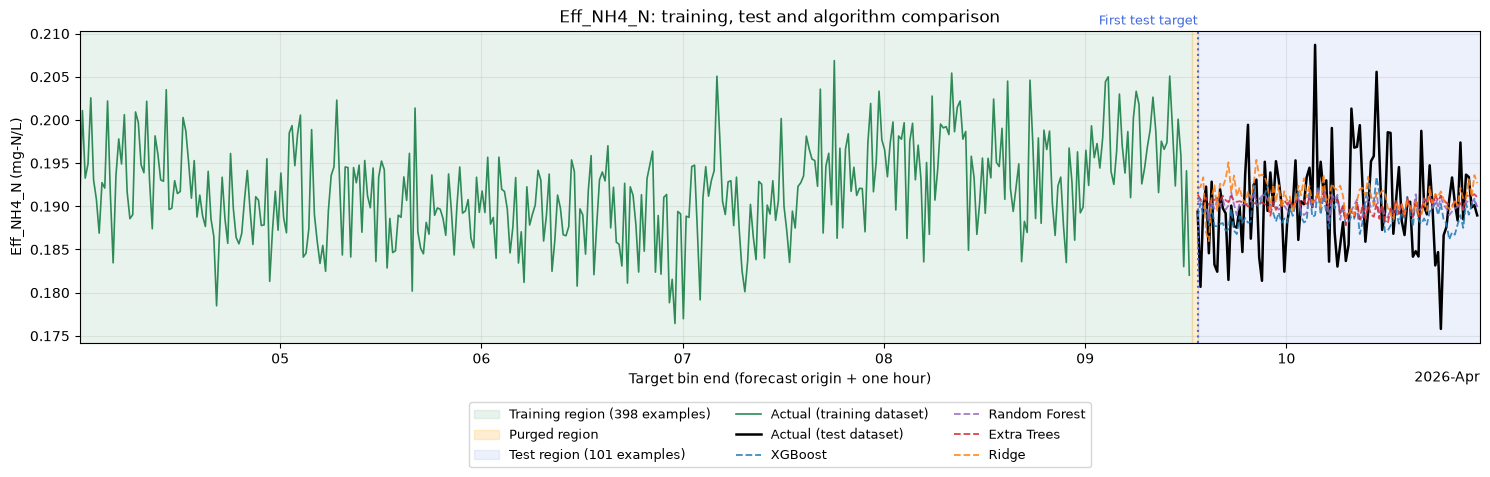

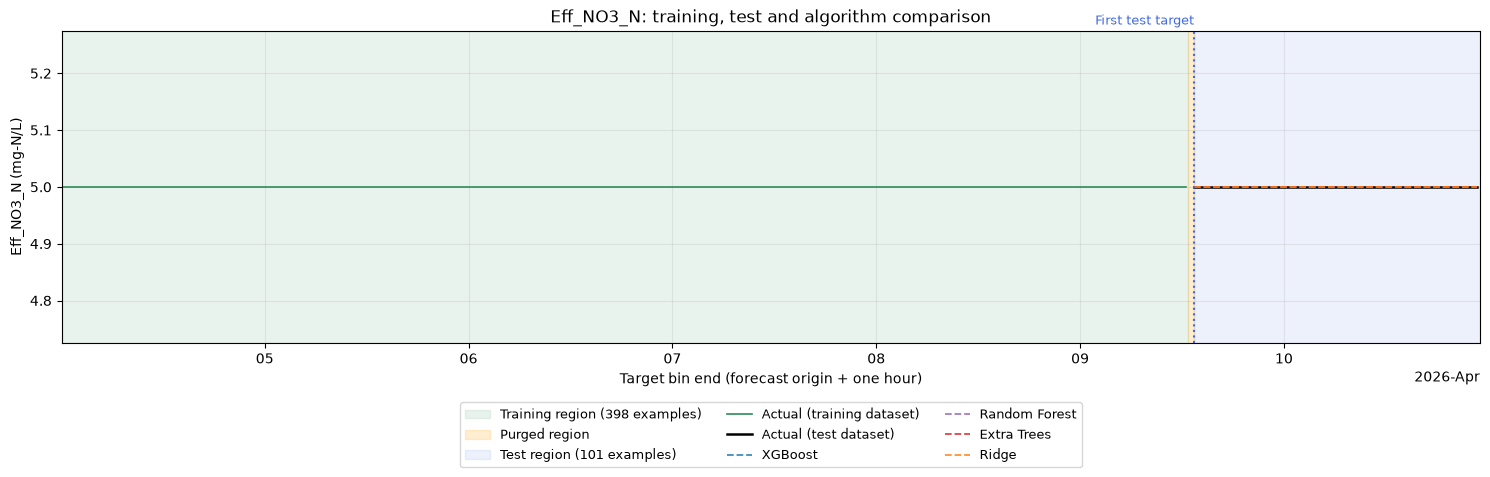

In [10]:
for name, cfg in MODEL_CONFIGS.items():
    results = comparison_predictions[name]
    actual_train = splits[name]["y_train"]
    train_times = actual_train.index + FORECAST_HORIZON
    test_times = pd.DatetimeIndex(results["target_available_at"])
    train_end = train_times.max() + CADENCE
    test_start = test_times.min()
    fig, ax = plt.subplots(figsize=(15, 5))
    ax.axvspan(train_times.min(), train_end, color="seagreen", alpha=0.10,
               label=f"Training region ({len(actual_train)} examples)")
    if train_end < test_start:
        ax.axvspan(train_end, test_start, color="orange", alpha=0.18,
                   label="Purged region")
    ax.axvspan(test_start, test_times.max() + CADENCE, color="royalblue", alpha=0.09,
               label=f"Test region ({len(results)} examples)")
    ax.plot(train_times, actual_train, color="seagreen", linewidth=1.2,
            label="Actual (training dataset)")
    ax.plot(test_times, results["actual"], color="black", linewidth=1.8,
            label="Actual (test dataset)")
    for key, color in ESTIMATOR_COLORS.items():
        ax.plot(test_times, results[key], color=color, linewidth=1.3,
                linestyle="--", alpha=0.85, label=ESTIMATOR_LABELS[key])
    ax.axvline(test_start, color="royalblue", linestyle=":")
    ax.text(test_start, 1.01, "First test target", transform=ax.get_xaxis_transform(),
            ha="right", va="bottom", color="royalblue", fontsize=9)
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set(xlabel="Target bin end (forecast origin + one hour)",
           ylabel=f"{cfg['target']} (mg-N/L)",
           title=f"{cfg['target']}: training, test and algorithm comparison")
    ax.set_xlim(train_times.min(), test_times.max() + CADENCE)
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}_algorithm_comparison_overview.png", dpi=150, bbox_inches="tight")
    plt.show()


## Save comparison results

Save the table, shared test predictions, model parameters and fitted estimators. Models retain the original training-only fit. Reload each additional estimator and check that its predictions are unchanged. Joblib files are local artifacts; only load files from trusted sources.


In [11]:
comparison_metrics.to_csv(OUTPUT_DIR / "algorithm_comparison_metrics.csv")
comparison_parameters = {}
for name, fitted in comparison_models.items():
    comparison_predictions[name].to_csv(OUTPUT_DIR / f"{name}_algorithm_comparison_predictions.csv")
    comparison_parameters[name] = {}
    for key, estimator in fitted.items():
        comparison_parameters[name][key] = estimator.get_params(deep=True)
        if key != "xgboost":
            path = OUTPUT_DIR / f"{name}_{key}.joblib"
            joblib.dump(estimator, path)
            restored = joblib.load(path)
            np.testing.assert_allclose(restored.predict(splits[name]["X_test"]),
                                       comparison_predictions[name][key], rtol=1e-6)
(OUTPUT_DIR / "algorithm_comparison_parameters.json").write_text(
    json.dumps(comparison_parameters, indent=2, default=str) + "\n"
)
print(f"Saved comparison metrics, predictions, plots and verified models in {OUTPUT_DIR}")


Saved comparison metrics, predictions, plots and verified models in /home/bryan1010/projects/ao-mbr-data-pipeline/notebooks/data/effluent_training_20min


## Results from this run

Both models used **398 training origins and 101 held-out origins**, with two origins purged before testing. The test origins span **2026-04-09 12:25 through 2026-04-10 21:45**; their target bins end one hour later.

| Target | Estimator | MAE (mg-N/L) | RMSE (mg-N/L) | R² |
|---|---|---:|---:|---:|
| NH3 task (`Eff_NH4_N`) | XGBoost | 0.004171 | 0.005532 | -0.064584 |
| NH3 task (`Eff_NH4_N`) | Persistence | 0.005735 | 0.007248 | -0.827895 |
| NO3 (`Eff_NO3_N`) | Both | 0 | 0 | Undefined |

NH3 reduces MAE by **27.28%** and RMSE by **23.68%** against one-hour persistence, but its negative R² shows limited fit on this small holdout. NO3 is constant at **5.0** throughout the source; zero error cannot demonstrate skill at forecasting nitrate changes. Preserve these as preliminary baseline results and test on an independent later period with varied target observations before deployment. No parameters were selected using test performance.

Models, predictions, metrics, figures and metadata were saved under `data/effluent_training_20min/`. Both serialized models were reloaded and their test predictions checked successfully.


### Algorithm comparison

On the same 101 held-out NH3 targets, Random Forest has the lowest MAE (**0.004053**) and RMSE (**0.005405 mg-N/L**), with **29.33% MAE skill** against persistence. XGBoost MAE is **0.004171**, Extra Trees **0.004155**, and Ridge **0.004424**. Differences are small and every fitted model has negative R² on this period; this does not establish a reliable winner across operating conditions. All NO3 estimators exactly match the constant 5.0 target, with undefined R² and baseline skill. New independent data is needed after this comparison.
